# StochVol: posterior samples versus prior

This notebook loads the ten saved SFMPE posterior sample sets and compares their marginal distributions with the configured StochVol prior. It also estimates the prior mass of the coordinate-wise Truncated region, using each saved posterior set as a proxy for the region-building sample.

**Interpretation caveat:** the selected run used `rounds: [1]`, so it completed without attempting a second-round Truncated proposal. Its saved 1,000 posterior samples per target are not the exact 2,048 samples used by the region builder in a multi-round run. The acceptance estimates below are therefore diagnostic estimates for a hypothetical next round, not a reconstruction of a failed run's exact bounds.

In [4]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import yaml
from scipy.stats import beta as beta_dist, binom, invgamma, norm
from IPython.display import Image, display

# Locate code/ from the notebook's current working directory.
search_roots = [Path.cwd().resolve(), *Path.cwd().resolve().parents]
CODE_ROOT = next(
    (
        candidate
        for root in search_roots
        for candidate in (root, root / "code")
        if (candidate / "src" / "sfmpe" / "tasks" / "StochVol.py").is_file()
    ),
    None,
)
if CODE_ROOT is None:
    raise FileNotFoundError("Could not locate code/src/sfmpe/tasks/StochVol.py")
sys.path.insert(0, str(CODE_ROOT / "src"))

from sfmpe.tasks.StochVol import StochVolPrior

RUN_DIR = CODE_ROOT / "results" / "stochvol_sfmpe_trunc_fix_100000_sims_1_round"
OUTPUT_DIR = RUN_DIR / "output"
SAMPLES_DIR = OUTPUT_DIR / "posterior_samples"

benchmark_config = yaml.safe_load(
    (RUN_DIR / "configs" / "benchmark.yaml").read_text(encoding="utf-8-sig")
)
task_config = yaml.safe_load(
    (RUN_DIR / "configs" / "benchmark_stochvol.yaml").read_text(encoding="utf-8-sig")
)
sfmpe_config = yaml.safe_load(
    (RUN_DIR / "configs" / "sfmpe_benchmark_stochvol.yaml").read_text(encoding="utf-8-sig")
)
prior_config = task_config["prior"]
prior = StochVolPrior(prior_config)

sample_paths = sorted(
    SAMPLES_DIR.glob("StochVol__SFMPE__100000__1__*.pt"),
    key=lambda path: int(path.stem.rsplit("__", 1)[-1]),
)
if not sample_paths:
    raise FileNotFoundError(f"No posterior sample files found in {SAMPLES_DIR}")
posterior_samples = torch.stack(
    [torch.load(path, map_location="cpu", weights_only=True) for path in sample_paths]
)
if posterior_samples.ndim != 3 or posterior_samples.shape[-1] != 4:
    raise ValueError(f"Unexpected posterior sample shape: {tuple(posterior_samples.shape)}")

prior_samples = prior.sample((500_000,)).cpu()
PARAMETER_NAMES = ["mu", "phi", "sigma", "m"]
CENTRAL_MASS = float(sfmpe_config["proposal"]["params"]["quantile"])
PADDING = float(sfmpe_config["proposal"]["params"].get("padding", 0.1))
MAX_PRIOR_DRAWS = int(sfmpe_config["proposal"]["params"].get("max_prior_draws", 1_000_000))

print(f"Loaded {len(sample_paths)} targets x {posterior_samples.shape[1]} posterior draws x 4 parameters")
print(f"Configured rounds: {benchmark_config['rounds']}")
print(f"Truncated region settings: mass={CENTRAL_MASS:g}, padding={PADDING:g}, max_prior_draws={MAX_PRIOR_DRAWS:,}")
print(f"Posterior tensor shape: {tuple(posterior_samples.shape)}")

Loaded 10 targets x 1000 posterior draws x 4 parameters
Configured rounds: [1]
Truncated region settings: mass=0.9, padding=0.1, max_prior_draws=1,000,000
Posterior tensor shape: (10, 1000, 4)


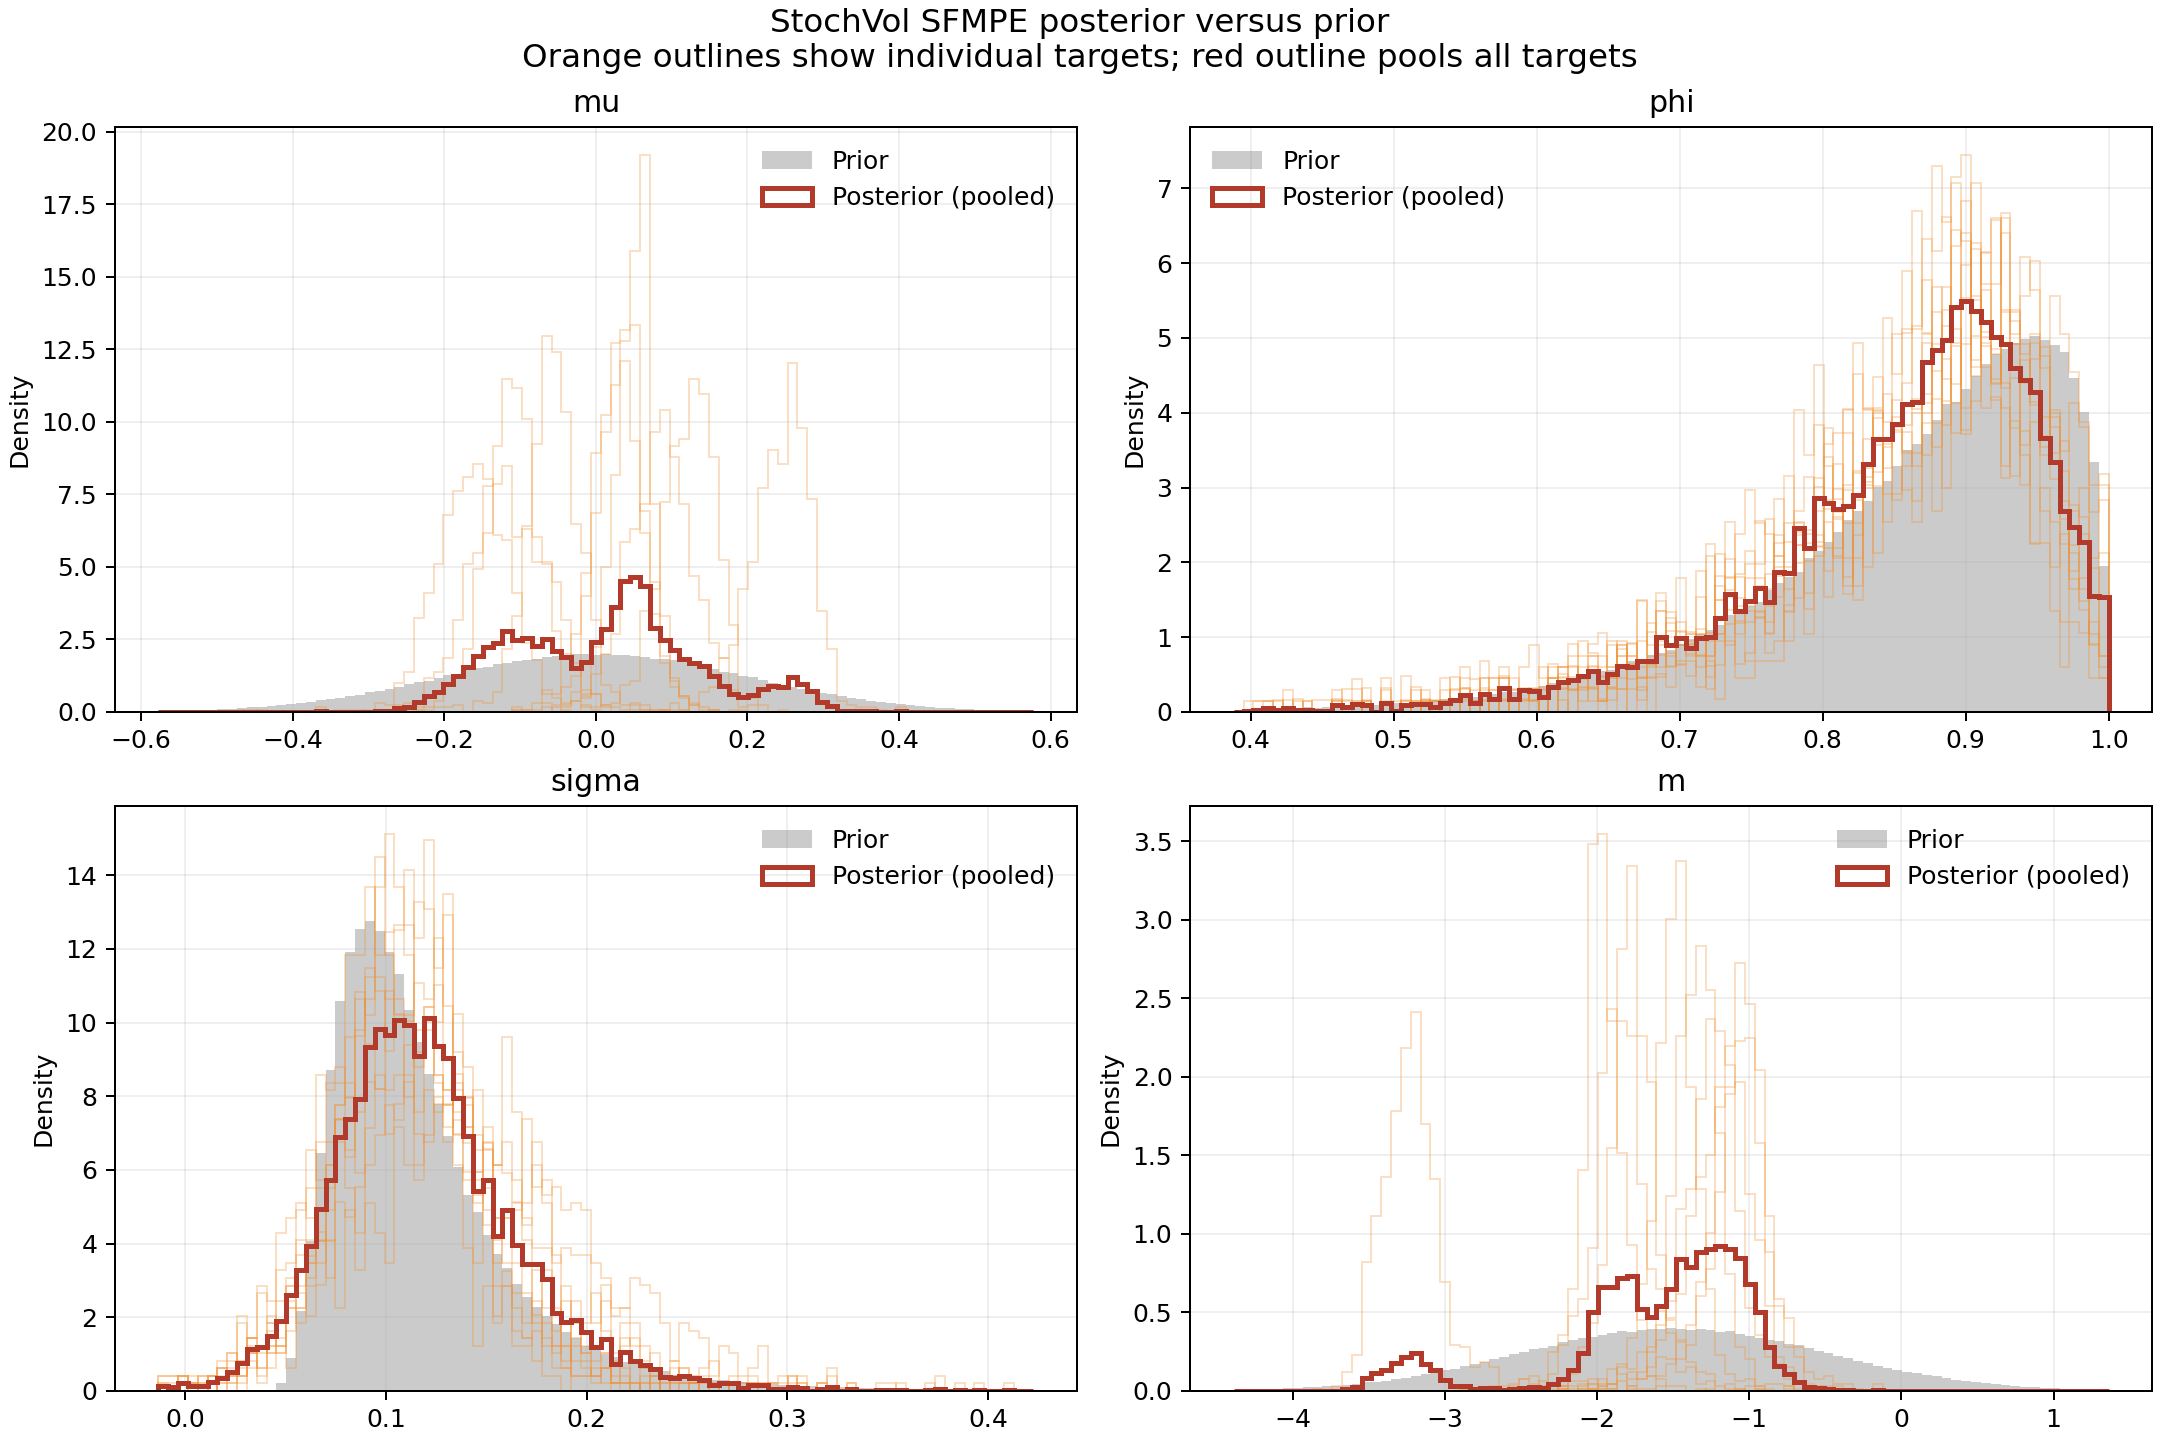

In [5]:
posterior_array = posterior_samples.numpy()
prior_array = prior_samples.numpy()

fig, axes = plt.subplots(2, 2, figsize=(12, 8), constrained_layout=True)
for parameter_index, ax in enumerate(axes.flat):
    prior_values = prior_array[:, parameter_index]
    pooled_posterior = posterior_array[:, :, parameter_index].reshape(-1)
    lower = float(min(np.quantile(prior_values, 0.002), np.quantile(pooled_posterior, 0.002)))
    upper = float(max(np.quantile(prior_values, 0.998), np.quantile(pooled_posterior, 0.998)))
    if parameter_index == 1:
        lower, upper = max(lower, -1.0), min(upper, 1.0)
    bins = np.linspace(lower, upper, 90)

    ax.hist(prior_values, bins=bins, density=True, color="0.55", alpha=0.45, label="Prior")
    for target_samples in posterior_array:
        ax.hist(
            target_samples[:, parameter_index], bins=bins, density=True,
            histtype="step", linewidth=0.8, color="#f28e2b", alpha=0.28,
        )
    ax.hist(
        pooled_posterior, bins=bins, density=True,
        histtype="step", linewidth=2.0, color="#b23a2b", label="Posterior (pooled)",
    )
    ax.set_title(PARAMETER_NAMES[parameter_index])
    ax.set_ylabel("Density")
    ax.grid(alpha=0.2)
    ax.legend(frameon=False)

fig.suptitle(
    "StochVol SFMPE posterior versus prior\n"
    "Orange outlines show individual targets; red outline pools all targets",
    fontsize=13,
)
figure_path = OUTPUT_DIR / "figures" / "StochVol_posterior_vs_prior.png"
figure_path.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(figure_path, dpi=180)
plt.close(fig)
display(Image(filename=str(figure_path)))

In [6]:
def prior_interval_mass(lower: float, upper: float, parameter_index: int) -> float:
    """Exact marginal prior probability for one interval under StochVolPrior."""
    if parameter_index == 0:  # mu ~ Normal
        return float(
            norm.cdf(upper, loc=prior_config["mu_loc"], scale=prior_config["mu_scale"])
            - norm.cdf(lower, loc=prior_config["mu_loc"], scale=prior_config["mu_scale"])
        )
    if parameter_index == 1:  # phi = 2 * Beta - 1
        lower, upper = max(lower, -1.0), min(upper, 1.0)
        if upper <= lower:
            return 0.0
        return float(
            beta_dist.cdf((upper + 1.0) / 2.0, prior_config["phi_alpha"], prior_config["phi_beta"])
            - beta_dist.cdf((lower + 1.0) / 2.0, prior_config["phi_alpha"], prior_config["phi_beta"])
        )
    if parameter_index == 2:  # sigma = sqrt(InvGamma)
        lower = max(lower, 0.0)
        if upper <= lower:
            return 0.0
        return float(
            invgamma.cdf(upper**2, a=prior_config["sigma_ig_shape"], scale=prior_config["sigma_ig_scale"])
            - invgamma.cdf(lower**2, a=prior_config["sigma_ig_shape"], scale=prior_config["sigma_ig_scale"])
        )
    if parameter_index == 3:  # m ~ Normal
        return float(
            norm.cdf(upper, loc=prior_config["m_loc"], scale=prior_config["m_scale"])
            - norm.cdf(lower, loc=prior_config["m_loc"], scale=prior_config["m_scale"])
        )
    raise IndexError(parameter_index)


def truncated_region_for_target(samples: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
    """Mirror the axis-aligned posterior quantiles and padding used by Truncated."""
    tail_mass = (1.0 - CENTRAL_MASS) / 2.0
    lower = np.quantile(samples, tail_mass, axis=0)
    upper = np.quantile(samples, 1.0 - tail_mass, axis=0)
    width = upper - lower
    return lower - PADDING * width, upper + PADDING * width


rows = []
for replicate, samples in enumerate(posterior_array):
    lower, upper = truncated_region_for_target(samples)
    marginal_masses = [
        prior_interval_mass(float(lower[j]), float(upper[j]), j)
        for j in range(len(PARAMETER_NAMES))
    ]
    # StochVolPrior samples its four parameters independently, so the box mass
    # is the product of the four marginal interval probabilities.
    box_mass = float(np.prod(marginal_masses))
    expected_draws = float("inf") if box_mass == 0.0 else 100_000 / box_mass
    rows.append(
        {
            "replicate": replicate,
            "target seed": 2026 + replicate,
            "prior mass: mu": marginal_masses[0],
            "prior mass: phi": marginal_masses[1],
            "prior mass: sigma": marginal_masses[2],
            "prior mass: m": marginal_masses[3],
            "box prior mass": box_mass,
            "expected prior draws for 100k accepted": expected_draws,
            "P(success | 50k requested)": float(binom.sf(50_000 - 1, MAX_PRIOR_DRAWS, box_mass)),
            "P(success | 33,334 requested)": float(binom.sf(33_334 - 1, MAX_PRIOR_DRAWS, box_mass)),
            "P(success | 100k requested)": float(binom.sf(100_000 - 1, MAX_PRIOR_DRAWS, box_mass)),
            "expected draws exceed max": expected_draws > MAX_PRIOR_DRAWS,
            "bounds": list(zip(lower.tolist(), upper.tolist())),
        }
    )

region_report = pd.DataFrame(rows)
display(
    region_report.drop(columns="bounds").style.format(
        {
            "prior mass: mu": "{:.3f}",
            "prior mass: phi": "{:.3f}",
            "prior mass: sigma": "{:.3f}",
            "prior mass: m": "{:.3f}",
            "box prior mass": "{:.4f}",
            "expected prior draws for 100k accepted": "{:,.0f}",
            "P(success | 50k requested)": "{:.3e}",
            "P(success | 33,334 requested)": "{:.3e}",
            "P(success | 100k requested)": "{:.3e}",
        }
    )
)
print(
    "Posterior support fraction (all saved draws):",
    float(((posterior_array[:, :, 1] > -1) & (posterior_array[:, :, 1] < 1) & (posterior_array[:, :, 2] > 0)).mean()),
)
print(
    "Interpretation: if the estimated box prior mass is p, obtaining 100,000 accepted draws takes about 100,000/p prior proposals on average. A low p can exceed max_prior_draws; the run's actual failure should still be checked against its exact bounds and attempt counter.",
)

region_report.to_json(OUTPUT_DIR / "StochVol_truncated_region_acceptance_estimates.json", orient="records", indent=2)

,replicate,target seed,prior mass: mu,prior mass: phi,prior mass: sigma,prior mass: m,box prior mass,expected prior draws for 100k accepted,P(success | 50k requested),"P(success | 33,334 requested)",P(success | 100k requested),expected draws exceed max
0,0,2026,0.320,0.958,0.965,0.324,0.0960,"1,041,942",1.000e+00,1.000e+00,2.601e-42,True
1,1,2027,0.227,0.969,0.924,0.219,0.0444,"2,250,756",2.748e-155,1.000e+00,0.000e+00,True
2,2,2028,0.262,0.951,0.969,0.332,0.0801,"1,248,032",1.000e+00,1.000e+00,0.000e+00,True
3,3,2029,0.185,0.962,0.890,0.194,0.0307,"3,253,548",0.000e+00,3.296e-50,0.000e+00,True
4,4,2030,0.231,0.959,0.937,0.227,0.0471,"2,123,147",3.578e-42,1.000e+00,0.000e+00,True
5,5,2031,0.152,0.949,0.938,0.308,0.0416,"2,401,984",0.000e+00,1.000e+00,0.000e+00,True
6,6,2032,0.267,0.937,0.959,0.252,0.0604,"1,655,000",1.000e+00,1.000e+00,0.000e+00,True
7,7,2033,0.305,0.920,0.983,0.354,0.0978,"1,022,479",1.000e+00,1.000e+00,8.189e-14,True
8,8,2034,0.269,0.968,0.913,0.222,0.0529,"1,889,438",1.000e+00,1.000e+00,0.000e+00,True
9,9,2035,0.259,0.969,0.921,0.108,0.0249,"4,021,191",0.000e+00,0.000e+00,0.000e+00,True


Posterior support fraction (all saved draws): 0.9469
Interpretation: if the estimated box prior mass is p, obtaining 100,000 accepted draws takes about 100,000/p prior proposals on average. A low p can exceed max_prior_draws; the run's actual failure should still be checked against its exact bounds and attempt counter.


## How to read the diagnostic

The four marginal plots reveal which posterior coordinates move into low-prior-density regions. The table multiplies their exact interval probabilities because the StochVol prior factorizes across parameters. A small box prior mass means rejection sampling is intrinsically expensive: the expected number of prior proposals for 100,000 accepted parameter vectors is approximately `100,000 / box prior mass`.

This gives a direct check against `max_prior_draws`, but it is not itself proof that a task failed: the run represented here has one round only. To diagnose a failed multi-round task precisely, save or log the exact posterior-derived bounds and the accepted/attempted count for the failing round, then compare that empirical acceptance rate with this estimate.